In [21]:
import pandas as pd

df = pd.read_csv("../data/raw/consumption.csv", sep=";", decimal=",", thousands=".")
print(df.shape)
print(df.columns.tolist())
df.head()

(17568, 6)
['Datum von', 'Datum bis', 'Netzlast [MWh] Berechnete Auflösungen', 'Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen', 'Pumpspeicher [MWh] Berechnete Auflösungen', 'Residuallast [MWh] Berechnete Auflösungen']


,Datum von,Datum bis,Netzlast [MWh] Berechnete Auflösungen,Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen,Pumpspeicher [MWh] Berechnete Auflösungen,Residuallast [MWh] Berechnete Auflösungen
0,04.11.2024 00:00,04.11.2024 01:00,41731.75,42781.25,1049.50,36022.00
1,04.11.2024 01:00,04.11.2024 02:00,40586.00,42814.75,2228.75,35627.25
2,04.11.2024 02:00,04.11.2024 03:00,40344.50,42333.75,1989.25,35997.00
3,04.11.2024 03:00,04.11.2024 04:00,40757.75,42713.00,1955.25,36830.25
4,04.11.2024 04:00,04.11.2024 05:00,42584.00,44599.00,2015.00,38937.75


In [22]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 17568 entries, 0 to 17567
Data columns (total 6 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Datum von                                                 17568 non-null  str    
 1   Datum bis                                                 17568 non-null  str    
 2   Netzlast [MWh] Berechnete Auflösungen                     17568 non-null  float64
 3   Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen  17568 non-null  float64
 4   Pumpspeicher [MWh] Berechnete Auflösungen                 17568 non-null  float64
 5   Residuallast [MWh] Berechnete Auflösungen                 17568 non-null  float64
dtypes: float64(4), str(2)
memory usage: 823.6 KB

Missing values per column:
Datum von                                                   0
Datum bis                                                   0
Netzl

In [ ]:
# 1. Convert date columns to actual datetime objects
df["Datum von"] = pd.to_datetime(df["Datum von"], format="%d.%m.%Y %H:%M")
df['Datum bis'] = pd.to_datetime(df['Datum bis'])

# 2. Clean numeric columns and convert them to float numbers
numeric_cols = [
    'Netzlast [MWh] Berechnete Auflösungen', 
    'Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen', 
    'Pumpspeicher [MWh] Berechnete Auflösungen', 
    'Residuallast [MWh] Berechnete Auflösungen'
]

for col in numeric_cols:
    df[col] = df[col].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False).astype(float)

# 3. Verify the updated data types
df.info()

ValueError: time data "13.11.2024 00:00" doesn't match format "%m.%d.%Y %H:%M". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [ ]:
# 1. Convert date columns to actual datetime objects
df['Datum von'] = pd.to_datetime(df['Datum von'])
df['Datum bis'] = pd.to_datetime(df['Datum bis'])

# 2. Clean numeric columns and safely convert dashes to NaN (missing values)
numeric_cols = [
    'Netzlast [MWh] Berechnete Auflösungen', 
    'Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen', 
    'Pumpspeicher [MWh] Berechnete Auflösungen', 
    'Residuallast [MWh] Berechnete Auflösungen'
]

for col in numeric_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace('.', '', regex=False)
        .str.replace(',', '.', regex=False)
    )
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 3. Verify the updated data types and check for any missing values
df.info()
print("\nMissing values after cleaning:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 264 entries, 0 to 263
Data columns (total 6 columns):
 #   Column                                                    Non-Null Count  Dtype         
---  ------                                                    --------------  -----         
 0   Datum von                                                 264 non-null    datetime64[us]
 1   Datum bis                                                 264 non-null    datetime64[us]
 2   Netzlast [MWh] Berechnete Auflösungen                     258 non-null    float64       
 3   Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen  258 non-null    float64       
 4   Pumpspeicher [MWh] Berechnete Auflösungen                 259 non-null    float64       
 5   Residuallast [MWh] Berechnete Auflösungen                 258 non-null    float64       
dtypes: datetime64[us](2), float64(4)
memory usage: 12.5 KB

Missing values after cleaning:
Datum von                                                   0
D

Matplotlib is building the font cache; this may take a moment.


<Axes: title={'center': 'German Electricity Consumption'}, xlabel='Datum von'>

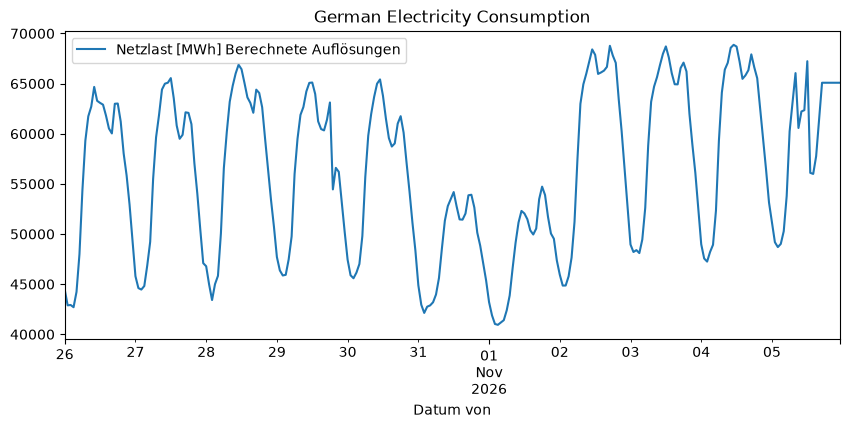

In [ ]:
# Fill missing values using forward fill (carry the previous hour's value forward)
df = df.ffill()

# Quick plot to visualize the energy consumption trend
df.plot(x='Datum von', y='Netzlast [MWh] Berechnete Auflösungen', figsize=(10, 4), title='German Electricity Consumption')

In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Create a simple lag feature: predict consumption based on the previous hour's value
df['Lag_1'] = df['Netzlast [MWh] Berechnete Auflösungen'].shift(1)
df_model = df.dropna(subset=['Lag_1'])

# Define X (input) and y (target)
X = df_model[['Lag_1']]
y = df_model['Netzlast [MWh] Berechnete Auflösungen']

# Train model
model = LinearRegression()
model.fit(X, y)

print("Model trained successfully!")
print(f"Coefficient: {model.coef_[0]:.4f}")
print(f"Intercept: {model.intercept_:.4f}")

Model trained successfully!
Coefficient: 0.9499
Intercept: 2898.6307


In [ ]:
print(df.columns.tolist())
display(df.head())

from sklearn.metrics import mean_absolute_error

target = "Netzlast [MWh] Berechnete Auflösungen"
split = int(len(df_model) * 0.8)
train, test = df_model.iloc[:split], df_model.iloc[split:]

model = LinearRegression().fit(train[["Lag_1"]], train[target])
pred = model.predict(test[["Lag_1"]])
print("MAE (MWh):", mean_absolute_error(test[target], pred))

['Datum von', 'Datum bis', 'Netzlast [MWh] Berechnete Auflösungen', 'Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen', 'Pumpspeicher [MWh] Berechnete Auflösungen', 'Residuallast [MWh] Berechnete Auflösungen', 'Lag_1']


,Datum von,Datum bis,Netzlast [MWh] Berechnete Auflösungen,Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen,Pumpspeicher [MWh] Berechnete Auflösungen,Residuallast [MWh] Berechnete Auflösungen,Lag_1
0,2026-10-26 00:00:00,2026-10-26 01:00:00,44466.27,48204.21,3737.95,-991.58,NaN
1,2026-10-26 01:00:00,2026-10-26 02:00:00,42888.96,47297.12,4408.16,-2015.79,44466.27
2,2026-10-26 02:00:00,2026-10-26 03:00:00,42925.27,47582.19,4656.92,-1841.01,42888.96
3,2026-10-26 03:00:00,2026-10-26 04:00:00,42701.48,47321.54,4620.06,-1427.68,42925.27
4,2026-10-26 04:00:00,2026-10-26 05:00:00,44229.80,47914.33,3684.53,1746.42,42701.48


MAE (MWh): 2211.4899358329294


In [ ]:
print(df.shape)
print(df["Datum von"].min(), df["Datum von"].max())

(264, 7)
2026-10-26 00:00:00 2026-11-05 23:00:00


In [24]:
print(df.shape)
print(df["Datum von"].min(), df["Datum von"].max())

(17568, 6)
01.01.2025 00:00 31.12.2025 23:00


In [25]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

target = "Netzlast [MWh] Berechnete Auflösungen"

d = df[["Datum von", target]].copy()
d["Datum von"] = pd.to_datetime(d["Datum von"], dayfirst=True)
d = d.sort_values("Datum von").reset_index(drop=True)
print(d["Datum von"].min(), d["Datum von"].max(), len(d))

# Features: past values and calendar information
d["lag_1"] = d[target].shift(1)       # 1 hour ago
d["lag_24"] = d[target].shift(24)     # same hour yesterday
d["lag_168"] = d[target].shift(168)   # same hour last week
d["hour"] = d["Datum von"].dt.hour
d["dayofweek"] = d["Datum von"].dt.dayofweek
d = d.dropna().reset_index(drop=True)

features = ["lag_1", "lag_24", "lag_168", "hour", "dayofweek"]

# Train on the first 80% of the time, test on the last 20%
split = int(len(d) * 0.8)
train, test = d.iloc[:split], d.iloc[split:]

model = HistGradientBoostingRegressor(random_state=42)
model.fit(train[features], train[target])
pred = model.predict(test[features])

print("Baseline MAE (same as previous hour):", round(mean_absolute_error(test[target], test["lag_1"]), 1))
print("Model MAE:", round(mean_absolute_error(test[target], pred), 1))
print("Average load (MWh):", round(test[target].mean(), 1))

2024-11-04 00:00:00 2026-11-05 23:00:00 17568


/var/folders/kw/pfv2zt650c74y_pwlgkm6_lr0000gn/T/ipykernel_33678/2618760364.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["dayofweek"] = d["Datum von"].dt.dayofweek


Baseline MAE (same as previous hour): 1627.9
Model MAE: 607.4
Average load (MWh): 50948.3
